# Capstone: Define and Solve an ML Problem

In [1]:
import pandas as pd
import numpy as np
import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler
import time

**Note**: As you work through the notebook, you can import additional packages as needed.

## Overview


In this capstone assignment, you will follow the machine learning life cycle and implement one of the supervised learning models you have learned so far in this course, along with a neural network, to solve a predictive problem.

This capstone spans two lab sessions.

- **Unit 5 Lab:** You will define a machine learning problem, explore and prepare your data, and train, test, evaluate and improve a traditional machine learning model (Parts 1–5).
- **Unit 6 Lab:** After completing Unit 6 on neural networks, you will apply a neural network to the same problem and compare the two approaches (Parts 6–7).

There is a checkpoint at the end of Part 5 that marks where to stop during the Unit 5 lab.

You will complete the following:

1. Choose your Data Set and Build Your DataFrame
2. Define Your ML Problem
3. Understand Your Data
4. Prepare Your Data
5. Train, Test, Evaluate and Improve a Traditional Machine Learning Model *(Unit 5 lab)*
6. Train, Test, Evaluate and Improve Neural Network *(Unit 6 lab)*
7. Compare Your Models and Reflect *(Unit 6 lab)*

**This is an individual assignment.** You are welcome to discuss ideas with your peers, but the code and written responses you submit must be your own.

**Note:** This capstone is intentionally less scaffolded than your weekly labs; that is by design. You are expected to make your own implementation choices, add code cells as needed, and document your reasoning throughout.

## Part 1: Choose Your Data Set and Build Your DataFrame


You will choose one of two data sets to work with for this capstone. In both cases, you will be solving a supervised learning binary classification problem by predicting one of two possible class labels. Both data sets have been used earlier in the course, so you are already familiar with their structure. 

**Option A: Census Income Data** (`censusData.csv`)
This data set contains demographic and employment information from the 1994 U.S. Census. You will use it to predict whether an individual's annual income exceeds $50,000. Your label column is `income_binary`, which contains two values: `<=50K` and `>50K`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Option B: Airbnb NYC Listings Data** (`airbnbListingsData.csv`)
This data set contains information about Airbnb listings in New York City. You will use it to predict whether a listing is high-priced. The data set includes a new `price_category` column that classifies each listing as either "high price" or "low price" based on whether the listing’s price falls above or below the 75th percentile of all listing prices. Listings at or above the 75th percentile are labeled as `high`, while the remaining listings are labeled as `low`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Note:**  These versions of the data sets differ slightly from the versions you have worked with in this program. For example, they may not include some of the preprocessing necessary for specific models. 

#### Load a Data Set and Save it as a Pandas DataFrame

The code cell below contains filenames (path + filename) for the two data sets available to you.

<b>Task:</b> In the code cell below, load your chosen data set using `pd.read_csv()` and save it to a DataFrame named `df`. Then call `df.head()` to inspect the first few row of the data set.

In [2]:
# File paths for both data sets
census_filename = os.path.join(os.getcwd(), "data_capstone", "censusData.csv")
airbnb_filename = os.path.join(os.getcwd(), "data_capstone", "airbnbListingsData.csv")

# Load your chosen dataset and save it to df
df = pd.read_csv(census_filename, header=0)

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex_selfID,capital-gain,capital-loss,hours-per-week,native-country,income_binary
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Non-Female,2174,0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Non-Female,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Non-Female,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Non-Female,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


## Part 2: Define Your ML Problem

The first step of the machine learning life cycle involves defining your business problem. In the markdown cell below, you will clearly define what you are trying to predict and why it matters. 

<b>Task</b>: In the markdown cell below, answer all of the following questions:

1. Which data set did you choose?
2. What is your label? What are you predicting?
3. What features do you plan to use? (This list may change after you explore your data.)
5. Why does this problem matter? Using the business brief you read in the lab overview page, explain how the organization described there could use a model that predicts this label to create value or inform decisions for their client.

1. I chose the census income data set.
2.The label I am choosing is the income binary to predict how many individuals exceed the 50,000 threshold and if race/gender has anything to do with it despite having proper education. 
3. The features I have chosen is education, sex_selfID, occupation and work class. What I am predicting is how many individuals whose annual income exceeds $50,000 based off gender and race. We will use the education feature to highlight if it makes a difference and their race to see if their is a marganilized bias against people of color/females. 
4. This problem matters because have representation matters. If there is a situation where someone is qualified and can relate to a certain topic and speak on the behalf of the community. This person should be in the room not under a glass ceiling. This shows company bias or how much they value inclusivity because they believe in opportunity for all. Higher morale leads to more success and avoiding hostile environments for those who are trying to ascend into a higher position. Companies should be more honest about their core values and if they can uphold said values this also leads to a lawsuit if candidates they know are looking for that specific company versus someone who will give their life and never know if they have what it takes to move up.


## Part 3: Understand Your Data

Now that you have defined your problem, perform exploratory data analysis (EDA) with that problem in mind. Consider the following as you inspect your data:

1. What data preparation techniques would you like to use? These data preparation techniques may include:

    * handling missing values
    * finding and replacing outliers
    * performing feature engineering techniques such as one-hot encoding on categorical features
    * selecting appropriate features and removing irrelevant features
    * addressing class imbalance


2. What machine learning model would you like to use that is suitable for your predictive problem and data?
   * You may use one of the following models that you have worked with so far:
        - K-Nearest Neighbors (KNN)
        - Decision Tree
        - Logistic Regression
   * Are there other data preparation techniques that you will need to apply to build a balanced modeling data set for your problem and model? For example, will you need to scale your data?
 

3. How will you evaluate and improve the model's performance?
    * Are there specific evaluation metrics or methods that are appropriate for your problem, dataset, or selected model?
    
<b>Task</b>: In the code cells below, use the techniques you have learned in this course to inspect and analyze your data.

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

### Class Imbalance

Examine the distribution of your label column to determine whether class imbalance is present. Use at least one visualization to show the class distribution. In the **EDA Summary** below, you will discuss how you plan to address any observed imbalance during data preparation.

<=50K    24720
>50K      7841
Name: income_binary, dtype: int64
<=50K    75.919044
>50K     24.080956
Name: income_binary, dtype: float64


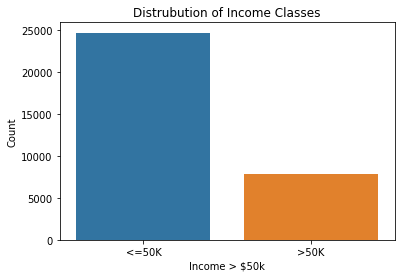

In [3]:
#checking the distrubution of the label
print(df['income_binary'].value_counts())

#show percentages
print(df['income_binary'].value_counts(normalize=True)* 100)

#visualization
plt.figure(figsize=(6,4))
sns.countplot(x='income_binary',data=df)
plt.title("Distrubution of Income Classes")
plt.xlabel("Income > $50k")
plt.ylabel("Count")
plt.show()

### Inspect and Analyze Your Data

Explore your features. Use summary statistics and visualizations to understand how your features are distributed and how they relate to the label. Identify issues such as missing values, outliers, or a feature that is irrelevant or redundant.

Think of the different techniques you have used to inspect and analyze your data in this course. These include using Pandas to apply data filters, using the Pandas `describe()` method to get insight into key statistics for each column, using the Pandas `dtypes` property to inspect the data type of each column, and using Matplotlib and Seaborn to detect outliers and visualize relationships between features and labels. 

Use at least one plot that visualizes a relationship between features and the label.

In [4]:
#looking at data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             32399 non-null  float64
 1   workclass       30725 non-null  object 
 2   fnlwgt          32561 non-null  int64  
 3   education       32561 non-null  object 
 4   education-num   32561 non-null  int64  
 5   marital-status  32561 non-null  object 
 6   occupation      30718 non-null  object 
 7   relationship    32561 non-null  object 
 8   race            32561 non-null  object 
 9   sex_selfID      32561 non-null  object 
 10  capital-gain    32561 non-null  int64  
 11  capital-loss    32561 non-null  int64  
 12  hours-per-week  32236 non-null  float64
 13  native-country  31978 non-null  object 
 14  income_binary   32561 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 3.7+ MB


In [5]:
#checking what is in the data
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32399.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32236.000000
mean,38.589216,1.897784e+05,10.080679,615.907773,87.303830,40.450428
std,13.647862,1.055500e+05,2.572720,2420.191974,402.960219,12.353748
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,14084.000000,4356.000000,99.000000


In [6]:
#checking how many null values are in our dataset
df.isnull().sum()


age                162
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex_selfID           0
capital-gain         0
capital-loss         0
hours-per-week     325
native-country     583
income_binary        0
dtype: int64

In [7]:
#checking for duplicates
print("Duplicate Rows: ", df.duplicated().sum())

Duplicate Rows:  22


In [8]:
#looking at categorical variables
categorical_cols=["education","sex_selfID","occupation","workclass"]

for col in categorical_cols:
    print("\n",col)
    print(df[col].value_counts())


 education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: education, dtype: int64

 sex_selfID
Non-Female    21790
Female        10771
Name: sex_selfID, dtype: int64

 occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: occupation, dtype: int64

 workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            129

<function matplotlib.pyplot.show>

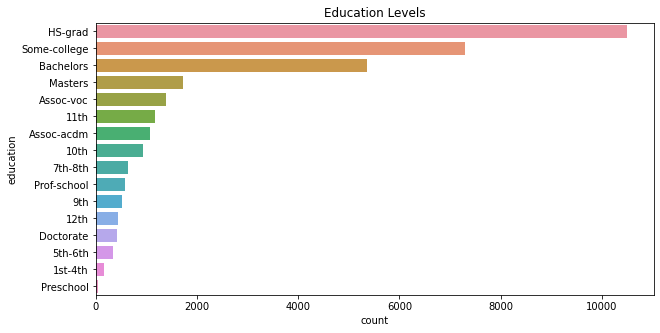

In [9]:
#visualization
plt.figure(figsize=(10,5))
sns.countplot(
    y = "education",
    data=df,
    order=df["education"].value_counts().index
)

plt.title("Education Levels")
plt.show

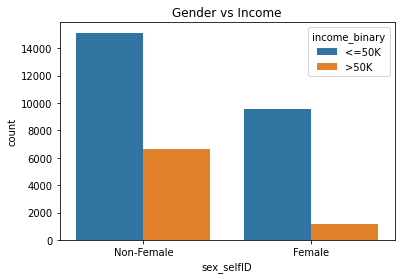

In [10]:
plt.figure(figsize=(6,4))

sns.countplot(
x="sex_selfID",
hue="income_binary",
data=df
)

plt.title("Gender vs Income")
plt.show()

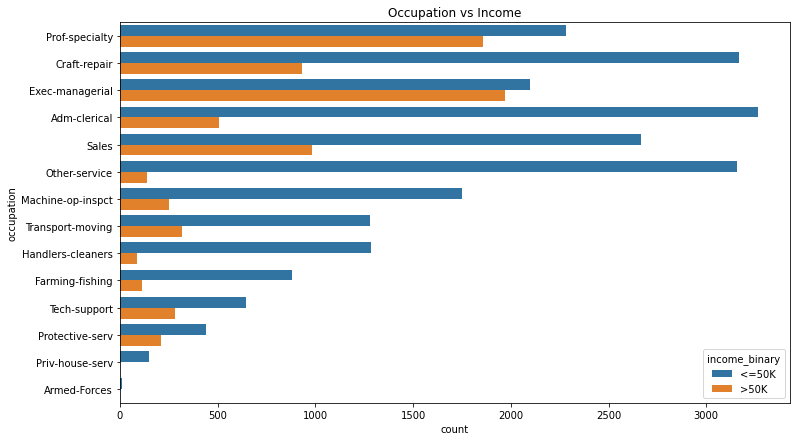

In [11]:
plt.figure(figsize=(12,7))

sns.countplot(
y="occupation",
hue="income_binary",
data=df,
order=df["occupation"].value_counts().index
)

plt.title("Occupation vs Income")
plt.show()


### EDA Summary

<b>Task</b>: In the markdown cell below, summarize the key findings from your data exploration. Describe any patterns, anomalies, or data quality issues you identified and explain how those findings may influence your data preparation decisions. For example, your exploration may affect how you handle missing values, address class imbalance, or determine which features to keep or remove.

During exploratory data analysis, I found that the income classes are imbalanced, with approximately 76% of individuals earning $50,000 or less and about 24% earning more than $50,000. Several columns contain missing values, including age, workclass, occupation, hours-per-week, and native-country, which will need to be handled before training the model. There are also 22 duplicate rows that should be removed during data preparation. The education distribution shows that most individuals have a high school diploma or some college education. The relationship plots suggest that education level, occupation, and sex appear to have an influence on whether an individual earns more than $50,000. Since my selected model will be Logistic Regression, I will convert categorical variables using one-hot encoding and scale the numerical features because Logistic Regression performs better when features are on similar scales. I will also evaluate the model using both accuracy and F1 score because the classes are somewhat imbalanced.

### Ethical Considerations:

Machine learning models can cause harm when they reflect or amplify biases in the data they are trained on. 

<b>Task</b>: In the markdown cell below, answer both of the following questions:

1. What biases or ethical concerns might be present in your dataset? Think about who collected the data, how it was collected, and which groups of people appear in it. Are there features in the dataset that could serve as proxies for protected characteristics like race, gender, or socioeconomic status?
2. Who could be harmed by a model that makes incorrect predictions on this data, and how? Be specific about which groups are most at risk and what the real-world consequences of errors might look like.

1. This dataset includes demographic characteristics such as race, gender, education, occupation, and workclass. These features may reflect historical hiring practices or wage inequalities that existed when the data was collected. Because race and gender are protected characteristics, there is a risk that a machine learning model could learn patterns that reinforce existing societal biases instead of making fair predictions.
2. Incorrect predictions could negatively affect job applicants or employees if the model were used to make hiring or compensation decisions. Individuals from underrepresented groups could be harmed if the model unfairly predicts lower earning potential based on biased historical data. Because of this, the model should be used carefully and regularly evaluated for fairness across different demographic groups.

## Part 4: Prepare Your Data

<b>Task</b>: In the code cell below, prepare your data for modeling. The specific steps you take will depend on what you found during your EDA and which model you plan to use. 

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [12]:
#dropping duplicates
df.drop_duplicates()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex_selfID,capital-gain,capital-loss,hours-per-week,native-country,income_binary
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Non-Female,2174,0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Non-Female,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Non-Female,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Non-Female,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38.0,United-States,<=50K
32557,40.0,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Non-Female,0,0,40.0,United-States,>50K
32558,58.0,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40.0,United-States,<=50K
32559,22.0,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Non-Female,0,0,20.0,United-States,<=50K


In [13]:
# missing values
df.isnull().sum()

age                162
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex_selfID           0
capital-gain         0
capital-loss         0
hours-per-week     325
native-country     583
income_binary        0
dtype: int64

In [14]:
df["age"]= df["age"].fillna(df["age"].median())
df['hours-per-week']= df['hours-per-week'].fillna(df['hours-per-week'].median())

In [15]:
df["occupation"]=df["occupation"].fillna(df['occupation'].mode()[0])
df['workclass']=df['workclass'].fillna(df['workclass'].mode()[0])
df['native-country']=df['native-country'].fillna(df['native-country'].mode()[0])

In [16]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex_selfID        0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income_binary     0
dtype: int64

In [17]:
df["income_binary"] = df["income_binary"].map({
    "<=50K": 0,
    ">50K" : 1
})

In [18]:
df["income_binary"].value_counts()

0    24720
1     7841
Name: income_binary, dtype: int64

In [19]:
df = pd.get_dummies(df,drop_first=True)

I removed duplicate records to avoid giving extra weight to repeated observations during training. Missing values in the numeric columns (age and hours-per-week) were replaced with the median because the median is less sensitive to outliers than the mean. Missing values in the categorical columns (workclass, occupation, and native-country) were replaced with the mode, which preserves the most common category. I converted the target variable (income_binary) into a binary format (0 for <=50K and 1 for >50K) so it could be used by the classification model. Finally, I applied one-hot encoding to the categorical features to convert them into numerical variables that Logistic Regression can process.

### Data Preparation Summary:

<b>Task</b>: In the markdown cell below, document the data preparation steps you took. For each decision, explain why you made it. For example, why did you handle missing values the way you did? Why did you keep or remove certain features? If a preparation step depends on the model you selected (for example, scaling for KNN but not for a decision tree), explain that as well.

## Part 5: Train, Test, Evaluate, and Improve a Traditional Machine Learning Model

Now you will train, test and evaluate your model. You will also use model selection techniques to improve your model's performance by identifying the optimal hyperparameter configuration.

<b>Task</b>: In the code cells below, do the following:

1. Create labeled examples from the dataset
2. Create training and test sets out of the labeled examples 
3. Train, test and evaluate your model 
    * You must evaluate your model using accuracy and F1 score. Use `accuracy_score` and `f1_score` from `sklearn.metrics`. For the F1 score, use `average='binary'` since this is a binary classification problem. You will compare your model's performance to that of a neural network later in this capstone. Save the results of your evaluation metrics to variables for later comparison.
    * You may use additional evaluation metrics of your choosing.
4. Perform model selection through grid search cross-validation to identify optimal hyperparameter values for your model
5. Train, test and evaluate a final version of your model using the optimal hyperparameter configuration.
6. Interpret your model's outputs in the context of the business problem. Depending on the model you chose, this might mean:
    * KNN: Describe what your model's performance metrics tell you about its behavior. For example: How does accuracy change as you vary k? What does that suggest about the structure of your data?
    * Decision Tree: print or plot feature importances.
    * Logistic Regression: print or plot the model coefficients.



<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [20]:
# Create labeled examples from the dataset
X = df.drop("income_binary",axis=1)
y=df["income_binary"]

In [21]:
# Create training and test sets out of the labeled examples 
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [22]:
df["income_binary"] = df["income_binary"].replace({7841: 1})

In [23]:
print(df["income_binary"].unique())
print(df["income_binary"].value_counts())

[0 1]
0    24720
1     7841
Name: income_binary, dtype: int64


In [24]:
df["income_binary"] = df["income_binary"].replace({7841:1})

In [25]:
print(df["income_binary"].unique())

[0 1]


In [26]:
# Train, test and evaluate your model
model = LogisticRegression(max_iter=1000,random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print("Accuracy: ", accuracy)
print("F1 score: ",f1)

Accuracy:  0.7984031936127745
F1 score:  0.39963420210333794


In [28]:
# Perform model selection through grid search cross-validation (GridSearchCV)
# to identify optimal hyperparameter values for your model
param_grid = {
    "C":[0.01,0.1,1,10],
    "solver":["liblinear","lbfgs"]
}

grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,cv=5,scoring="accuracy")

grid.fit(X_train,y_train)

print("Best Parameters: ",grid.best_params_)
print("Best Score: ", grid.best_score_)

Best Parameters:  {'C': 10, 'solver': 'lbfgs'}
Best Score:  0.8007902386575132


In [29]:
# Train, test and evaluate a final version of your model using the optimal hyperparameter values.
best_model = grid.best_estimator_

best_model.fit(X_train,y_train)

y_pred = best_model.predict(X_test)

best_accuracy = accuracy_score(y_test,y_pred)
best_f1 = f1_score(y_test,y_pred)

print("Final Parameters: ", best_accuracy)
print("Final Score: ", best_f1)

Final Parameters:  0.7984031936127745
Final Score:  0.39963420210333794


In [30]:
# Interpret your model's outputs 
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": best_model.coef_[0]
})

coefficients = coefficients.sort_values(by="Coefficient", ascending=False)

print(coefficients.head(10))

                              Feature  Coefficient
4                        capital-loss     0.000778
29  marital-status_Married-civ-spouse     0.000378
3                        capital-gain     0.000361
36         occupation_Exec-managerial     0.000116
21                education_Bachelors     0.000102
24                  education_Masters     0.000066
51                  relationship_Wife     0.000047
9              workclass_Self-emp-inc     0.000040
26              education_Prof-school     0.000034
42          occupation_Prof-specialty     0.000029


### Model Reflection:

<b>Task</b>: In the markdown cell below, answer the following questions:

1. Which model did you choose and why? Reference your problem and data characteristics in your explanation.
2. What did you learn through the model selection process?
3. How do you interpret your model's outputs? What do the predictions or coefficients or feature importances actually mean in the context of your problem?
4. Are there any fairness or ethical concerns with your model? Who might be harmed by incorrect predictions, and are any groups more likely to be affected?

1. I selected Logistic Regression because the problem is a binary classification task that predicts whether an individual's income exceeds $50K. Logistic Regression is well suited for binary classification, provides interpretable results, and serves as a strong baseline model.
2. GridSearchCV tested multiple hyperparameter combinations using cross-validation. This process identified the parameter values that produced the best validation performance and reduced the likelihood of choosing parameters based solely on a single train-test split.

3. Logistic Regression assigns a coefficient to every feature. Positive coefficients increase the likelihood that an observation belongs to the income greater than $50K class, while negative coefficients decrease that likelihood. Features with larger absolute coefficient values have the strongest influence on the model's predictions.

4. One goal of this project is to examine whether education alone explains income differences or whether demographic characteristics such as race and gender also influence the model's predictions. If protected characteristics have a strong impact, this may indicate historical bias in the data rather than true differences in qualifications.This dataset may reflect historical bias because it includes sensitive features such as race, gender, education, and occupation. If the model learns that certain genders or demographic groups are less likely to earn more than $50,000, it may reinforce existing inequalities rather than measure actual ability or qualifications. Education may be a legitimate predictor of income, but when combined with protected characteristics like race or gender, the model could unintentionally learn unfair patterns that place people into different income categories based on historical discrimination rather than merit. Therefore, the model should be evaluated for fairness before being used to support employment or compensation decisions.

---
## ✔️ Unit 5 Checkpoint

**Stop here.** If you have completed Parts 1 through 5, you are done with the Unit 5 portion of this capstone.

Parts 6 and 7 require you to train and evaluate a neural network. You will learn about neural networks in the Unit 6 asynchronous content. Do not start Part 6 until you have completed that material and your lab facilitator has directed you to continue. Do not submit your work for grading until you complete Parts 6 and 7.

Make sure your notebook is saved before you close it.

---
## Part 6: Train, Test, Evaluate and Improve a Neural Network

> **⚠️ Before you write any code in Part 6, do this first.**
> 
> Your notebook does not retain variables between sessions. All of your variables and everything else need to be restored to memory before any code below will work.
> 
> Go to **Kernel > Restart & Run All** to re-run Parts 1 through 5, then scroll back here to continue. If you skip this step, you will see a `NameError` on the first code cell below.

Now you will apply a neural network to the same problem and dataset. You will use Keras to build a feedforward neural network for binary classification.

The scaffolding below will walk you through the steps. Where you see a **Task**, fill in the code. Where you see a **Decision**, you are making an independent choice about your architecture or training process. For each decision, add a comment explaining what you chose and why.


### Prepare Your Data for the Neural Network

Neural networks require all input features to be numeric and scaled. If your features are on very different scales (for example, one feature ranges from 0 to 90 and another from 0 to 99999), the model may train less effectively and have difficulty learning meaningful patterns from the data.

Before training your network, create scaled versions of your training and test data. Use `StandardScaler()` from `sklearn.preprocessing` to standardize your features: 

<b>Task</b>: Complete the code cell below to fit the scaler on your training data, then transform both training and test sets. Save the results to new variables (for example, `X_train_scaled` and `X_test_scaled`) so your original data remains available for reference.

**Note:** Use your scaled data for all neural network steps below.

In [31]:
# Scale your data for the neural network

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

### Step 1: Define Your Model Architecture

You will use the Keras `Sequential` class to build your network. Your network should have:

- An input layer with the correct shape for your data
- At least two hidden layers using the `Dense` class
- An output layer appropriate for binary classification

<b>Task:</b> Create a `Sequential` model object and name it `nn_model`. Then construct and add each layer.

**Decision:** How many hidden layers will you use? How many units in each? What activation function will you use for the hidden layers? Add a comment explaining your choices.

In [32]:
# Get the number of features in your training data
n_features = X_train_scaled.shape[1]

# Create the neural network model
nn_model = keras.Sequential()

# Create the input layer and add the input layer to the 'nn_model' object
nn_model.add(Input(shape=(n_features,)))

# Create the hidden layers and add the hidden layers to the 'nn_model' object
# Decision: How many layers? How many units? What activation function?
#I chose 64 neurons with ReLU because it can learn complex relationships while staying efficient.
nn_model.add(Dense(64,activation="relu"))

#I added a second layer with 32 neurons to capture additional patterns.
nn_model.add(Dense(32,activation="relu"))
# Create the output layer and add the output layer to the 'nn_model' object
#I added a third layer with 16 neurons as an extra safe guard.
nn_model.add(Dense(16,activation="relu"))
# Use the correct number of units and activation function for binary classification
nn_model.add(Dense(1,activation="sigmoid"))

# Print a summary of your model
nn_model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                6272      
_________________________________________________________________
dense_1 (Dense)              (None, 32)                2080      
_________________________________________________________________
dense_2 (Dense)              (None, 16)                528       
_________________________________________________________________
dense_3 (Dense)              (None, 1)                 17        
Total params: 8,897
Trainable params: 8,897
Non-trainable params: 0
_________________________________________________________________


### Step 2:  Define the Optimization Function

<b>Task:</b> In the code cell below, create an optimizer object. Use stochastic gradient descent (SGD) with a learning rate of your choosing.

**Decision:** What learning rate will you use? Add a comment explaining your choice.

In [33]:
# Decision: What learning rate will you use? Add a comment explaining your decision.
#I chose a learning rate of 0.01 because it provides stable learning without causing the model to overshoot the minimum.
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01)

### Step 3: Define the Loss Function

<b>Task:</b> In the code cell below, create a binary cross entropy loss function using `keras.losses.BinaryCrossentropy()`. Use  the parameter `from_logits=False`. 

In [34]:
loss_fn = keras.losses.BinaryCrossentropy(from_logits=False)

### Step 4: Compile the Model

<b>Task:</b> In the code cell below, package the network architecture with the optimizer and the loss function using the `compile()` method. Use the `accuracy` evaluation metric.

In [35]:
nn_model.compile(
    optimizer=sgd_optimizer,
    loss=loss_fn,
    metrics=["accuracy"]
)

### Step 5: Fit the Model to the Training Data

We will define our own callback class to output information from our model while it is training. Make sure you execute the code cell below so that it can be used in subsequent cells.

<b>Task:</b> Use the `fit()` method to fit your model to the training data. Save the result to variable `history.`

Use the `validation_split` parameter to reserve a portion of your training data for validation during training (a common choice is `validation_split=0.2`). After each epoch, the model is evaluated on this validation data, allowing you to monitor how well the model generalizes and helping you detect overfitting.

Also, use the the logger class defined above to track training progress.

**Decision:** How many epochs will you train for? Add a comment explaining your choice.

**Note:** This may take a while to run.

In [36]:
class ProgBarLoggerNEpochs(keras.callbacks.Callback):
    
    def __init__(self, num_epochs: int, every_n: int = 50):
        self.num_epochs = num_epochs
        self.every_n = every_n
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n == 0:
            s = 'Epoch [{}/ {}]'.format(epoch + 1, self.num_epochs)
            logs_s = ['{}: {:.4f}'.format(k.capitalize(), v)
                      for k, v in logs.items()]
            s_list = [s] + logs_s
            print(', '.join(s_list))


In [38]:
# Decision: How many epochs? Add a comment.
# I chose 800 because it was a common number that would work before so I am trying this as a base. 

t0 = time.time() # start time

num_epochs = 800 

history = nn_model.fit(
X_train_scaled,
y_train,
validation_split=0.2,
epochs=num_epochs,
batch_size=32,
callbacks=[ProgBarLoggerNEpochs(num_epochs, every_n=50)],
verbose=0
)

t1 = time.time() # stop time

print('Elapsed time: %.2fs' % (t1-t0))

Epoch [50/ 800], Loss: 0.1618, Accuracy: 0.9240, Val_loss: 0.7761, Val_accuracy: 0.8284
Epoch [100/ 800], Loss: 0.1534, Accuracy: 0.9281, Val_loss: 0.8517, Val_accuracy: 0.8211
Epoch [150/ 800], Loss: 0.1449, Accuracy: 0.9322, Val_loss: 0.9440, Val_accuracy: 0.8225
Epoch [200/ 800], Loss: 0.1398, Accuracy: 0.9341, Val_loss: 1.0237, Val_accuracy: 0.8169
Epoch [250/ 800], Loss: 0.1334, Accuracy: 0.9374, Val_loss: 1.0893, Val_accuracy: 0.8092
Epoch [300/ 800], Loss: 0.1316, Accuracy: 0.9383, Val_loss: 1.2077, Val_accuracy: 0.8202
Epoch [350/ 800], Loss: 0.1227, Accuracy: 0.9440, Val_loss: 1.2794, Val_accuracy: 0.8117
Epoch [400/ 800], Loss: 0.1198, Accuracy: 0.9443, Val_loss: 1.3213, Val_accuracy: 0.8069
Epoch [450/ 800], Loss: 0.1182, Accuracy: 0.9460, Val_loss: 1.3821, Val_accuracy: 0.8119
Epoch [500/ 800], Loss: 0.1136, Accuracy: 0.9476, Val_loss: 1.4231, Val_accuracy: 0.8027
Epoch [550/ 800], Loss: 0.1083, Accuracy: 0.9500, Val_loss: 1.5094, Val_accuracy: 0.8086
Epoch [600/ 800], Loss

### Step 6: Visualize Training Performance

<b>Task:</b>  

Create two plots to visualize the model's performance over time:
1. Training loss and validation loss over epochs, on the same axes.
2. Training accuracy and validation accuracy over epochs, on the same axes.

Label your axes and include a legend.

Use the `history` object returned by `fit()` to obtain this information. 



In [ ]:
# Plot training loss and validation loss over epochs
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot training accuracy and validation accuracy over epochs
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Step 7: Evaluate the Model's Performance on the Test Set

<b>Task:</b> Use your neural network to generate predictions on the test set and evaluate its performance using accuracy and F1 score. Use `nn_model.predict()` to generate predictions. Since `nn_model.predict()` returns probabilities, apply a threshold of 0.5 to convert probabilities into binary class predictions before computing your metrics. Save your accuracy and F1 score results to clearly named variables so you can compare them to the results from your previous model. Print the results.

In [40]:
# Generate predictions from your neural network using your scaled test data
# nn_model.predict() returns probabilities — apply a threshold of 0.5 to get class labels

y_prob=nn_model.predict(X_test_scaled)

y_pred_nn= (y_prob > 0.5).astype(int)

In [41]:
# Compute accuracy and F1 score for the neural network and print the results

nn_accuracy = accuracy_score(y_test,y_pred_nn)
nn_f1 = f1_score(y_test,y_pred_nn)

print("Neural Network Accuracy:", nn_accuracy)
print("Neurnal Network F1 Score:", nn_f1)

Neural Network Accuracy: 0.8151389528635038
Neurnal Network F1 Score: 0.6002656042496679


#### Neural Network Reflection:

<b>Task:</b> In the markdown cell below, answer the following questions:

1. Walk through the architecture decisions you made: number of layers, number of units, activation functions, learning rate, and number of epochs. Why did you make each of those choices?
2. What did your training curves tell you? Did you see any signs of overfitting or underfitting?
3. How did your neural network perform on the test set? Report your accuracy and F1 score here and note whether the result surprised you given what your training curves showed.

1. I designed a feedforward neural network with an input layer, three hidden layers containing 64,32, and 16 neurons, and a single output neuron. I used the ReLU activation function in each hidden layer because it is computationally efficient and helps the network learn complex,nonlinear relationships while reducing problems such as vanishing gradients. For the output layer, I used a sigmoid activation function because this is a binary classification problem that predicts whether an individual's income exceeds $50,000. I selected a learning rate of 0.01 with the Stochastic Gradient Descent (SGD) optimizer because it provides stable learning while avoiding updates that are too large.I trained the model for 800 epochs to give the network sufficient time to learn the underlying patterns in the training data while monitoring both the training and validation metrics. 

2.  The training curves showed evidence of overfitting. The training accuracy continued increasing to approximately 94–95%, while the validation accuracy remained around 80–82%. In addition, the training loss decreased while the validation loss increased substantially. This suggests that the model began memorizing the training data rather than learning patterns that generalized well to new data.


3.  On the test set, the neural network achieved an accuracy of approximately 82% and an F1 score of approximately 60% . These results were better with what the training curves suggested. I thought overfitting may be present but, the neural networks generalized well enough to outpeform Logistic Regression on the test data. 


## Part 7: Compare Your Models and Reflect

You have now applied two different approaches to the same problem. In this final section, you will put those results side by side and reflect on what you learned.

###  Results Summary

<b>Task:</b> In the code cell below, create a summary table using a Pandas DataFrame that displays each evaluation metric for both models side by side. Use the variables you created for the accuracy and F1 score metrics. The table should make it easy to compare performance at a glance across every metric you computed.

In [43]:
# Build a side-by-side comparison of your two models using the metric variables
# you created. For example:
#
results = pd.DataFrame({
     'Metric': ['Accuracy', 'F1 Score'],
     'Logistic Regression': [accuracy, f1],
     'Neural Network': [nn_accuracy, nn_f1]
 })
print(results.to_string(index=False))
#
# YOUR CODE HERE

   Metric  Logistic Regression  Neural Network
 Accuracy             0.798403        0.815139
 F1 Score             0.399634        0.600266


### Comparative Analysis

<b>Task:</b> In the markdown cell below, write a comparative analysis that addresses the following. 

1. **Performance comparison.** How did the two models perform relative to each other? Which metrics improved, which stayed the same, and which got worse?

2. **Was the added complexity worth it?** Neural networks are more complex to build, tune, and interpret. Given the performance difference you observed, do you think the neural network justified that added complexity for this problem?

3. **Recommendation.** If you were presenting this work to your company and their client as described in the business brief, which model would you recommend deploying and why? Consider not just performance but also interpretability, training time, and what the costs of different types of errors look like for that specific client.

4. **What you would do next.** If you had more time, what would you try to improve your results? This could include trying different architectures, additional preprocessing steps, different features, or techniques to address class imbalance. Be specific.

1. The Neural Network performed better than the Logistic Regression model. Logistic Regression achieved an accuracy of 79.84% and an F1 score of 0.3996, while the Neural Network achieved an accuracy of 81.51% and an F1 score of 0.6003. The largest improvement was in the F1 score, showing that the Neural Network was much better at correctly identifying the positive income class.
2. Although the Neural Network required more time to build and train, the higher accuracy and much better F1 score suggest that the additional complexity was worthwhile. The model was able to learn more complex patterns than Logistic Regression, even though it showed some signs of overfitting.
3. I would recommend deploying the Neural Network because it achieved the highest accuracy and F1 score. While Logistic Regression is simpler and easier to interpret, the Neural Network produced better predictive performance, making it the stronger choice for this classification task.
4. If I had more time, I would reduce overfitting by using techniques such as early stopping, dropout, or L2 regularization. I would also experiment with different numbers of hidden layers, neurons, learning rates, batch sizes, and epochs. Additionally, I would tune the classification threshold and address the class imbalance to see if the F1 score could be improved even further.

---
## AI Use Attestation

Reflect honestly on how you used AI tools during this capstone. You are expected to have used AI somewhere in your workflow, and your reflection on that use is what will be evaluated: How clearly you describe your choices, how you verified your work, and what you learned from the process. If you chose not to use AI, explain why. Answer each question in the markdown cell below.

1. Where and at what stages of this capstone did you use AI tools, for example, Claude during brainstorming, coding, or debugging? If you chose not to use AI, explain why.
2. Identify one part of the capstone that required the most effort or thought. What made it challenging, and how did you work through it, with AI or without AI? If you used AI at this point, feel free to share a prompt that worked well or one that did not land the way you expected.
3. How did you verify that your work was correct? What did you look for to catch a mistake, whether it came from AI output or your own reasoning?
4. What is one thing you would do differently next time, either in how you approached the capstone or in how you used AI during it?

1. Where I used AI the most was during writing the technical report analysis. I also used AI in the planning phase; I would brainstorm with ChatGPT about which approach to take. We would discuss the pros and cons of each one and which strategy would match the result. More importantly, whether it would align with the project's objective in the most precise way. 

2. The most effort would be in part one; a lot of thinking went into that before any code was worked on. As well, there was no instruction, so double-checking and going off gut instinct was a unique perspective. For most of these assignments, there are instructions on what we are looking for, a self-check, or grading with feedback. So planning the strategy of what is the best approach for the goal I was trying to achieve and why. I would argue with ChatGPT as to why certain weights or labels would need to be changed to make this project more realistic. Whereas I felt the AI agent would want the  code working but discredits the actual data. 

3. I would run the code in ChatGPT to make sure the logic was correct. Most of the work, I would compare from old assignments or look at documentation. If there was an error, I would try to solve it on my own with a simple Google search. If the error was too complexed I would bring it over to ChatGPT; for example, I lost the connection to the kernel or perhaps a missing import.

4. Next time, I would see if I could make it more advanced, scalable, or interactive. Learning from module 6 and reading into lab 7, I feel there is so much more I could have done with this project if I put in more proper time so the build is more intentional. 
